<a href="https://colab.research.google.com/github/y-adulyasak/SCOA_PhD/blob/main/S12_MDPRL/RL_Inventory_Optimization_PPO_SB3_S1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Snowblower planning: exact MDP and PPO in Stable-Baselines3

Here a snowblower dealer gets one feature it can observe, i.e., whether there is snow on the ground.

1. **The store and its two models**: without the indicator (state = stock) and with it (state = stock and indicator).
2. **Exact answers**: both MDPs as linear programs.
3. **What each rule costs in the real store**: the value of the indicator.
4. **PPO without the indicator.**
5. **PPO with the indicator.**
6. **All policies on the same simulated weeks.**
7. **Things to try.**


In [ ]:
%pip install -q stable-baselines3 gymnasium      # Colab: installs Stable-Baselines3 (PyTorch is already there)
%matplotlib inline
import time                                        # to time the training
import numpy as np                                 # arrays and random numbers
import matplotlib.pyplot as plt                    # charts
import torch                                       # the neural-network library under Stable-Baselines3
import gymnasium as gym                            # the standard interface for RL environments
from gymnasium import spaces                       # describes what the agent observes and which actions exist
from scipy.optimize import linprog                 # the exact answer: the MDP as a linear program
import stable_baselines3
from stable_baselines3 import PPO                  # the RL algorithm: an actor-critic
from stable_baselines3.common.env_util import make_vec_env     # runs several copies of an environment at once
from stable_baselines3.common.env_checker import check_env     # checks that an environment follows the interface

torch.set_num_threads(1)                           # tiny networks: one CPU thread is fastest
print("stable-baselines3", stable_baselines3.__version__, "| gymnasium", gym.__version__, "| torch", torch.__version__)

stable-baselines3 2.9.2 | gymnasium 1.4.0 | torch 2.15.0+cu132


## 1. Dealer problem

A dealer stocks snowblowers and has space for at most **7** units. Each Monday the manager can call **one small truck** from the regional warehouse, at **\$350 per delivery**; it arrives at once and brings as many snowblowers as fit, **up to 4**, so a truck at stock s brings min(4, 7 − s). Every Monday the weather service's **snow-depth report** shows whether there is snow on the ground in the city. In such a *snow week* demand is **3, 4 or 5** snowblowers; in a week *without snow* it is **0, 1 or 2**, each equally likely. Snow cover stays until next week with probability **0.8**. Each snowblower (a premium two-stage machine, about \$2,500) left in inventory at the end of the week costs **\$20**; a customer the store cannot supply gets one shipped from the warehouse, at **\$300** extra to the dealer.

$$\text{week cost} = 350\,a + 20\,s' + 300\,(d - s - q)^+, \qquad q = a\,\min(4, 7 - s), \qquad s' = (s + q - d)^+ .$$

Every snowblower demanded is bought and sold either way, so the purchase price does not change the decision and is left out.

| | model A: no indicator | model B: with the indicator |
|---|---|---|
| the manager looks at | stock s | stock s and the snow report w |
| demand in her model | 0 to 5, equally likely, independent weeks (the long-run mix) | 0–2 or 3–5 by week type; types persist |
| states | 8 | 16 |

In [ ]:
# ---- the store: change these numbers and re-run all cells ----
SMAX, CAP = 7, 4                          # shelf space; a truck brings at most 4
TRUCK, H, COURIER = 350.0, 20.0, 300.0    # $ per truck, $ per unit left on Sunday, $ per customer couriered
STAY = 0.8                                # P(next week has the same snow condition)
DEM = {0: (0, 2), 1: (3, 5)}              # demand range: w = 0 no snow, w = 1 snow on the ground
SCALE = 100.0                             # PPO's reward is -cost / SCALE (dollars -> numbers near 1)

def demand_pmf(w):
    """P(demand = d) when this week's snow condition is w: uniform on DEM[w]."""
    lo, hi = DEM[w]                                       # smallest and largest demand this week
    return {d: 1 / (hi - lo + 1) for d in range(lo, hi + 1)}   # each value equally likely, e.g. {3: 1/3, 4: 1/3, 5: 1/3}

def week_cost(s, a, d):
    """One week. Stock s, action a (1 = truck), demand d  ->  (cost in $, next week's stock)."""
    y = s + a * min(CAP, SMAX - s)        # stock after the truck: it brings as many as fit, up to CAP
    left = max(y - d, 0)                  # units left on Sunday (they are next Monday's stock)
    short = max(d - y, 0)                 # customers the store cannot supply: couriered from the warehouse
    return TRUCK * a + H * left + COURIER * short, left

def actions(s):
    return (0, 1) if s < SMAX else (0,)   # 0 = no truck, 1 = truck; no truck when the shelf is full

# twenty weeks of snow cover (S = snow on the ground, - = none)
rng = np.random.default_rng(1)            # random-number generator with a fixed seed (same output every run)
w, path = 0, ""                           # start without snow
for t in range(20):
    path += "S" if w else "-"             # record this week's condition
    if rng.random() >= STAY:              # with probability 1 - STAY = 0.2 ...
        w = 1 - w                         # ... the condition flips for next week
print("twenty weeks (S = snow on the ground, - = none):", path)

twenty weeks (S = snow on the ground, - = none): --SS---SSSSSSSSSSSSS


## 2. Exact MDPs as linear programs

Each model lists its states, the actions in each state, the expected week cost c and the next-state probabilities. One LP solver handles both: the variables x(state, a) are long-run shares of weeks, with one balance row per state (weeks that start there = weeks that end there) and Σ x = 1. These are the LPs of the workbook's NoSignal-LP and Signal-LP sheets.

In [ ]:
def model_A():
    """No indicator. State = (stock,). Demand: the long-run mix (half snow, half no-snow weeks), weeks independent.
    Returns states, c[state, a] = expected week cost, T[state, a] = {next state: probability}."""
    pmf = {}                                              # demand distribution of the mix: 0..5
    for w in (0, 1):
        for d, p in demand_pmf(w).items():
            pmf[d] = pmf.get(d, 0) + 0.5 * p              # half the weeks of each type -> P(d) = 1/6 for d = 0..5
    states = [(s,) for s in range(SMAX + 1)]              # 8 states: stock 0..7
    c, T = {}, {}
    for (s,) in states:
        for a in actions(s):
            c[(s,), a], T[(s,), a] = 0.0, {}
            for d, p in pmf.items():                      # average over this week's demand
                cost, nxt = week_cost(s, a, d)
                c[(s,), a] += p * cost                    # expected cost of the week
                T[(s,), a][(nxt,)] = T[(s,), a].get((nxt,), 0) + p   # P(next stock); several demands can end at 0
    return states, c, T

def model_B():
    """With the indicator. State = (stock, w). Demand from this week's w; w repeats with probability STAY."""
    states = [(s, w) for w in (0, 1) for s in range(SMAX + 1)]       # 16 states
    c, T = {}, {}
    for (s, w) in states:
        for a in actions(s):
            c[(s, w), a], T[(s, w), a] = 0.0, {}
            for d, p in demand_pmf(w).items():            # demand depends on this week's snow condition
                cost, nxt = week_cost(s, a, d)
                c[(s, w), a] += p * cost
                for w2 in (0, 1):                         # next week's snow condition
                    q = p * (STAY if w2 == w else 1 - STAY)          # P(demand d) x P(w2 | w)
                    T[(s, w), a][(nxt, w2)] = T[(s, w), a].get((nxt, w2), 0) + q
    return states, c, T

def solve_lp(states, c, T):
    """Average-cost MDP as an LP:  min sum c*x  s.t.  one balance row per state, sum x = 1, x >= 0.
    x[state, a] = long-run share of weeks in that state taking action a.
    Returns (cost per week g, policy P(truck | state), number of variables)."""
    pairs = list(c)                             # the variables: one per (state, action) pair
    row = {st: i for i, st in enumerate(states)}         # constraint row of each state
    A = np.zeros((len(states) + 1, len(pairs)))  # equality constraints A x = b
    for k, (st, a) in enumerate(pairs):
        A[row[st], k] += 1                      # weeks that start in st ...
        for nxt, p in T[st, a].items():
            A[row[nxt], k] -= p                 # ... minus weeks that end there: must be 0
    A[-1] = 1                                   # last row: the shares sum to 1
    b = np.r_[np.zeros(len(states)), 1]         # right-hand side: 0 for each balance row, 1 for the total
    res = linprog([c[pr] for pr in pairs], A_eq=A, b_eq=b, bounds=(0, None), method="highs")   # the simplex-type solver
    x = dict(zip(pairs, res.x))                 # optimal shares
    policy = {}
    for st in states:
        share = x[st, 0] + x.get((st, 1), 0)    # share of weeks in st
        policy[st] = x.get((st, 1), 0) / share if share > 1e-9 else 0.0   # P(truck | st); 0 if st is never visited
    return res.fun, policy, len(pairs)          # res.fun = minimal average cost per week

def show(policy, name):
    """Print a policy P(truck | s, w) as a grid."""
    print(name)
    print("   stock:   " + " ".join(f"{s:>5d}" for s in range(SMAX + 1)))
    for w, lab in ((0, "no snow"), (1, "snow   ")):
        cells = [" full" if s == SMAX else ("truck" if policy(s, w) >= 0.5 else "    -") for s in range(SMAX + 1)]
        print(f"   {lab}:  " + " ".join(cells))

gA, polA, nA = solve_lp(*model_A())             # model A: cost per week, policy, number of variables
gB, polB, nB = solve_lp(*model_B())             # model B
print(f"model A (no indicator):    8 states, {nA} LP variables, ${gA:.2f} per week in its own view")
print(f"model B (with indicator): 16 states, {nB} LP variables, ${gB:.2f} per week")
show(lambda s, w: polA[(s,)], "\nmodel A's optimal policy (the same in both rows: it ignores the snow report)")
show(lambda s, w: polB[(s, w)], "\nmodel B's optimal policy")

model A (no indicator):    8 states, 15 LP variables, $287.40 per week in its own view
model B (with indicator): 16 states, 30 LP variables, $269.46 per week

model A's optimal policy (the same in both rows: it ignores the snow report)
   stock:       0     1     2     3     4     5     6     7
   no snow:  truck truck truck truck     -     -     -  full
   snow   :  truck truck truck truck     -     -     -  full

model B's optimal policy
   stock:       0     1     2     3     4     5     6     7
   no snow:  truck truck     -     -     -     -     -  full
   snow   :  truck truck truck truck     -     -     -  full


Without the indicator the best policy is one reorder point: a truck when stock is 3 or less, so the store always has enough for a snow week. With it, the store can run down to 1 snowblower in a week without snow and orders at 3 when there is snow on the ground.

## 3. Model evaluations

Model A's cost (\$287.40) is its own estimate: it assumes each week's demand is independent of the weeks before, so it misses that snow on the ground tends to stay. To compare the two policies fairly, we evaluate both in the real store: each policy turns it into a Markov chain over (stock, snow), whose long-run cost we compute exactly.

In [ ]:
SB, cB, TB = model_B()                    # the real store behaves like model B: states, costs, transitions

def real_cost(policy):
    """Exact long-run cost per week in the real store of a policy P(truck | s, w).
    The policy turns the store into a Markov chain over (s, w); its cost is the chain's stationary average."""
    idx = {st: i for i, st in enumerate(SB)}               # matrix index of each state
    n = len(SB)
    P, cost = np.zeros((n, n)), np.zeros(n)                # transition matrix and expected week cost under the policy
    for st in SB:
        q = policy(*st) if st[0] < SMAX else 0.0          # probability of a truck in this state
        for a, pa in ((0, 1 - q), (1, q)):                 # mix the two actions with their probabilities
            if pa == 0:
                continue
            cost[idx[st]] += pa * cB[st, a]
            for nxt, p in TB[st, a].items():
                P[idx[st], idx[nxt]] += pa * p
    # stationary distribution pi (long-run share of weeks in each state): pi P = pi and sum(pi) = 1
    A = np.vstack([P.T - np.eye(n), np.ones(n)])
    pi = np.linalg.lstsq(A, np.r_[np.zeros(n), 1], rcond=None)[0]   # solve the (overdetermined) linear system
    return float(pi @ cost)                                # average cost per week = sum over states of share x cost

cost_A_real = real_cost(lambda s, w: polA[(s,)])           # model A's rule, run in the real store
cost_B_real = real_cost(lambda s, w: polB[(s, w)])         # model B's rule
print(f"model A's rule (stock <= 3) in the real store: ${cost_A_real:.2f} per week (its own model said ${gA:.2f})")
print(f"model B's rule in the real store:              ${cost_B_real:.2f} per week")
print(f"value of the indicator: ignoring it costs {cost_A_real / cost_B_real - 1:+.1%}")
for r in range(-1, 7):                                     # every single reorder point, ignoring the snow report
    print(f"   one reorder point for all weeks, stock <= {r:2d}: ${real_cost(lambda s, w: float(s <= r)):.2f}")

model A's rule (stock <= 3) in the real store: $288.27 per week (its own model said $287.40)
model B's rule in the real store:              $269.46 per week
value of the indicator: ignoring it costs +7.0%
   one reorder point for all weeks, stock <= -1: $750.00
   one reorder point for all weeks, stock <=  0: $357.18
   one reorder point for all weeks, stock <=  1: $300.34
   one reorder point for all weeks, stock <=  2: $287.50
   one reorder point for all weeks, stock <=  3: $288.27
   one reorder point for all weeks, stock <=  4: $306.46
   one reorder point for all weeks, stock <=  5: $339.87
   one reorder point for all weeks, stock <=  6: $383.19


The best single reorder point for the real store is in fact 2, slightly cheaper than model A's 3: model A treats weeks as independent, while in the store snow weeks come in runs and the stock itself carries part of that information. Either way, the snow report is worth about 7% a week here.

Here the decision repeats and today's truck changes next week's stock, so the rule has to account for future weeks: the MDP does this exactly (by solving an LP in this case) whereas RL learns the policy (rule) from simulation.

## 4. PPO without the indicator (model A)

The environment simulates model A: each week has snow on the ground with probability ½, independently, and the agent is not told which. The observation is the stock, given to the network **one-hot** (8 inputs, one per stock level); the action is truck or not (`Discrete(2)`); the truck brings as many units as fit. The reward is **−cost / 100**: in dollars, a week costs a few hundred, and networks train best on numbers near 1. (The optimal policy does not depend on this scale; the learning steps do.)

| setting | value | meaning |
|---|---|---|
| `n_envs`, `n_steps` | 4, 512 | collect 2,048 simulated weeks, then update |
| `batch_size` | 256 | minibatch size for the update passes |
| `gamma`, `gae_lambda` | 0.99, 0.95 | discount; how many weeks the advantage looks ahead |
| `learning_rate`, `clip_range`, `ent_coef` | 3·10⁻⁴, 0.2, 0.01 | step size; at most ±20% change per update; small exploration bonus |

**PPO is an actor–critic**, like the Excel workbook's learner, with three differences: neural networks instead of a formula and a table, batches of weeks instead of one week at a time, and a discount γ instead of the average cost ḡ.

- **Actor**: a small network (two hidden layers of 64) maps the observation to P(truck). In Excel: the logistic rule with weights θ.
- **Critic**: a second network of the same size estimates V(observation), the discounted reward still to come. In Excel: the table V(s, w).
- **Each update**: run 4 × 512 weeks with the current actor; compute TD errors δ = r + γV(s′) − V(s); average them over a few weeks into advantages (GAE, λ = 0.95); then make 10 passes of minibatch gradient steps. The actor's loss is −min(ratio × advantage, clipped ratio × advantage), where ratio = π<sub>new</sub>(a | s) / π<sub>old</sub>(a | s); the critic's loss is the squared gap between V and its target. In Excel the same two steps happen after every single week.

In [ ]:
# PPO settings (table above)
PPO_KW = dict(n_steps=512,          # weeks each environment copy simulates before an update (x 4 copies = 2,048)
              batch_size=256,       # minibatch size in the update passes
              gamma=0.99,           # discount: a week 100 weeks away still counts 0.99^100 = 0.37
              gae_lambda=0.95,      # GAE: how many weeks of TD errors each advantage averages (about 17 here)
              learning_rate=3e-4,   # step size of the gradient steps (Adam)
              clip_range=0.2,       # the new policy may move at most +-20% away from the old one per update
              ent_coef=0.01,        # small bonus for randomness: keeps exploring
              verbose=0)            # no training log

def one_hot(s):
    """Observation without the indicator: the stock as 8 inputs, 1 at position s."""
    v = np.zeros(SMAX + 1, np.float32)
    v[s] = 1.0                      # e.g. stock 2 -> [0, 0, 1, 0, 0, 0, 0, 0]
    return v

def obs_B(s, w):
    """Observation with the indicator (Section 5): one-hot stock plus w."""
    return np.append(one_hot(s), np.float32(w))

class NoSignalStore(gym.Env):
    """Model A as an environment: each week is snowy with probability 1/2, independently, and hidden from the agent.
    An episode is 104 weeks (two years); it is cut there (truncated), not ended, and the next one starts at a random stock."""
    def __init__(self, horizon=104):
        self.observation_space = spaces.Box(0.0, 1.0, shape=(SMAX + 1,), dtype=np.float32)   # 8 numbers in [0, 1]
        self.action_space = spaces.Discrete(2)               # 0 = no truck, 1 = truck
        self.horizon = horizon                               # weeks per episode
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)                             # seeds self.np_random
        self.t, self.s = 0, int(self.np_random.integers(0, SMAX + 1))   # week counter; random starting stock
        return one_hot(self.s), {}                           # first observation, no extra info
    def step(self, action):
        a = int(action) if self.s < SMAX else 0              # a full shelf cannot take a truck
        w = int(self.np_random.random() >= 0.5)              # this week's snow condition: 50/50, hidden
        lo, hi = DEM[w]
        d = int(self.np_random.integers(lo, hi + 1))         # this week's demand
        cost, self.s = week_cost(self.s, a, d)               # cost of the week; stock for next week
        self.t += 1
        # observation, reward, terminated (never: the store does not close), truncated (after `horizon` weeks), info
        return one_hot(self.s), -cost / SCALE, False, self.t >= self.horizon, {"cost": cost}

def greedy(model, with_snow):
    """The trained actor's most likely action in each state, as a policy P(truck | s, w) in {0, 1}."""
    def policy(s, w):
        if s >= SMAX:
            return 0.0                                       # full shelf: no truck
        obs = obs_B(s, w) if with_snow else one_hot(s)       # what the agent would observe in this state
        action, _ = model.predict(obs, deterministic=True)   # the actor's most likely action, no random draw
        return float(action)
    return policy

def highest_truck(policy, w):
    """Highest stock at which the policy sends a truck (-1: never)."""
    return max([s for s in range(SMAX) if policy(s, w) >= 0.5], default=-1)

def train(env_cls, with_snow, label, weeks=100_000, chunk=25_000, seed=0):
    """Train PPO on 4 copies of the environment. Every `chunk` weeks, grade the greedy policy exactly in the real store."""
    env = make_vec_env(env_cls, n_envs=4, seed=seed)         # 4 stores simulated side by side
    model = PPO("MlpPolicy", env, seed=seed, **PPO_KW)       # MlpPolicy: actor and critic networks, 2 hidden layers of 64
    log, t0 = [], time.time()
    for k in range(1, weeks // chunk + 1):
        model.learn(chunk, reset_num_timesteps=False)       # simulate and update; keep counting weeks across calls
        policy = greedy(model, with_snow)                    # the current actor, as a rule
        cost = real_cost(policy)                             # its exact cost in the real store
        log.append((k * chunk, cost))                        # for the learning curve in Section 6
        print(f"{label}: {k * chunk // 1000:3d}k weeks {time.time() - t0:4.0f}s | highest stock with a truck: "
              f"no snow {highest_truck(policy, 0)}, snow {highest_truck(policy, 1)} | "
              f"real-store cost ${cost:.2f} ({cost / cost_B_real - 1:+.1%} vs model B's optimum)")
    return model, log

check_env(NoSignalStore())                                  # Gymnasium's sanity check of the environment
ppo_A, log_A = train(NoSignalStore, False, "PPO, no indicator  ")
show(greedy(ppo_A, False), "\nPPO without the indicator")

PPO, no indicator  :  25k weeks    6s | highest stock with a truck: no snow 2, snow 2 | real-store cost $287.50 (+6.7% vs model B's optimum)


PPO, no indicator  :  50k weeks   12s | highest stock with a truck: no snow 2, snow 2 | real-store cost $287.50 (+6.7% vs model B's optimum)


PPO, no indicator  :  75k weeks   17s | highest stock with a truck: no snow 2, snow 2 | real-store cost $287.50 (+6.7% vs model B's optimum)


PPO, no indicator  : 100k weeks   23s | highest stock with a truck: no snow 2, snow 2 | real-store cost $287.50 (+6.7% vs model B's optimum)

PPO without the indicator
   stock:       0     1     2     3     4     5     6     7
   no snow:  truck truck truck     -     -     -     -  full
   snow   :  truck truck truck     -     -     -     -  full


## 5. PPO with the indicator (model B)

Now the environment is the real store: the snow report is part of the observation (one-hot stock plus w), and next week's type repeats with probability 0.8.

In [ ]:
class SignalStore(gym.Env):
    """Model B, the real store: the agent sees the stock and this week's snow report w; w repeats with probability STAY."""
    def __init__(self, horizon=104):
        self.observation_space = spaces.Box(0.0, 1.0, shape=(SMAX + 2,), dtype=np.float32)   # one-hot stock + w
        self.action_space = spaces.Discrete(2)               # 0 = no truck, 1 = truck
        self.horizon = horizon
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t = 0
        self.s = int(self.np_random.integers(0, SMAX + 1))   # random starting stock
        self.w = int(self.np_random.integers(0, 2))          # random starting snow condition
        return obs_B(self.s, self.w), {}
    def step(self, action):
        a = int(action) if self.s < SMAX else 0
        lo, hi = DEM[self.w]                                 # demand range for this week's (observed) condition
        d = int(self.np_random.integers(lo, hi + 1))
        cost, self.s = week_cost(self.s, a, d)
        self.t += 1
        if self.np_random.random() > STAY:                  # the snow condition flips with probability 0.2
            self.w = 1 - self.w
        return obs_B(self.s, self.w), -cost / SCALE, False, self.t >= self.horizon, {"cost": cost}

check_env(SignalStore())
ppo_B, log_B = train(SignalStore, True, "PPO, with indicator")
show(greedy(ppo_B, True), "\nPPO with the indicator")

PPO, with indicator:  25k weeks    6s | highest stock with a truck: no snow 2, snow 6 | real-store cost $291.86 (+8.3% vs model B's optimum)


PPO, with indicator:  50k weeks   11s | highest stock with a truck: no snow 0, snow 6 | real-store cost $272.71 (+1.2% vs model B's optimum)


PPO, with indicator:  75k weeks   17s | highest stock with a truck: no snow 0, snow 6 | real-store cost $272.71 (+1.2% vs model B's optimum)


PPO, with indicator: 100k weeks   23s | highest stock with a truck: no snow 0, snow 6 | real-store cost $269.85 (+0.1% vs model B's optimum)

PPO with the indicator
   stock:       0     1     2     3     4     5     6     7
   no snow:  truck     -     -     -     -     -     -  full
   snow   :  truck truck truck truck     - truck truck  full


The progress lines report the highest stock at which the policy sends a truck. A truck at a level the store almost never has in that week type (such as 5 or 6 in a snow week) shows up there but barely changes the cost as the states are not visited often.

In [ ]:
# Why the no-snow decision at stock 1 is a near tie
c13 = real_cost(lambda s, w: float(s <= (1 if w == 0 else 3)))   # the LP's rule: truck at <= 1 (no snow), <= 3 (snow)
c03 = real_cost(lambda s, w: float(s <= (0 if w == 0 else 3)))   # PPO's rule: wait until 0 without snow
print(f"long-run average cost: truck at stock <= 1 without snow ${c13:.2f} a week; wait until 0: ${c03:.2f} ({c03 / c13 - 1:+.2%})")

# PPO's objective is discounted (gamma = 0.99): solve it exactly by value iteration, V(s) = min_a [c + gamma * E V(s')]
gam = 0.99
V = {st: 0.0 for st in SB}                                       # start from 0 ...
for _ in range(5000):                                            # ... and apply the Bellman update until it settles
    V = {st: min(cB[st, a] + gam * sum(p * V[nxt] for nxt, p in TB[st, a].items()) for a in actions(st[0])) for st in SB}
Q = {a: cB[(1, 0), a] + gam * sum(p * V[nxt] for nxt, p in TB[(1, 0), a].items()) for a in (0, 1)}   # both actions at (1, no snow)
print(f"discounted (gamma = 0.99, PPO's objective), from stock 1 without snow: truck ${Q[1]:,.2f}, wait ${Q[0]:,.2f}")
print(f"one week's cost varies by about ${np.std([week_cost(1, 0, d)[0] for d in range(3)]):.0f} from demand alone")

long-run average cost: truck at stock <= 1 without snow $269.46 a week; wait until 0: $269.85 (+0.14%)
discounted (gamma = 0.99, PPO's objective), from stock 1 without snow: truck $26,741.28, wait $26,741.26
one week's cost varies by about $137 from demand alone


PPO learns the structure from the simulator alone: one reorder point without the indicator and two with it, with no demand distribution, no persistence probability and no cost formula.

- **Without the indicator** it settles on a reorder point of 2. In its own model (independent weeks) that costs about 1.9% more than the LP's 3: a small difference. (In the real store, 2 happens to be the best single reorder point.)
- **With the indicator** it waits until the shelf is empty in a week without snow. The cell above shows why: the two choices are practically tied. Under PPO's discounted objective waiting is in fact optimal; in the long-run average it costs 0.14% more.

**Inside the trained actor–critic.** The cell below asks PPO's two networks about each state. The actor gives P(truck). The critic gives V; converted back to dollars, −100·V is the discounted cost still to come. The last column is the exact value for the optimal policy, from the cell above.

The actor is close to the optimum, but the critic is not. After 100,000 weeks it is nearly flat at about \$9,000, while the exact discounted cost is about \$26,900, roughly 100 weeks of cost at γ = 0.99. Its level climbs slowly: it reaches the right range only after about 350,000 weeks, and only then do the differences between states appear (about \$1,000, the differential cost h).

PPO still learns a good actor for two reasons. Each advantage sums TD errors over about 17 weeks (GAE, λ = 0.95), and advantages are normalized in each batch. So with a flat critic, an advantage is simply a short run of actual costs. The Excel critic avoids the problem by subtracting ḡ: it learns only the differences h.

In [ ]:
states = [(s, w) for w in (0, 1) for s in range(SMAX)]          # every state where a truck is possible
obs = torch.as_tensor(np.array([obs_B(s, w) for s, w in states]))   # their observations, as one batch
with torch.no_grad():                                            # just reading the networks, no training
    p_truck = ppo_B.policy.get_distribution(obs).distribution.probs[:, 1].numpy()   # actor: P(truck | s, w)
    v = ppo_B.policy.predict_values(obs).squeeze(1).numpy()                         # critic: V(s, w), in reward units

print("state                 actor P(truck)   critic: cost to come ($)   exact, optimal policy ($)")
for (s, w), p, val in zip(states, p_truck, v):
    # reward = -cost / SCALE, so -SCALE * V is the critic's discounted cost still to come, in dollars
    print(f"stock {s}, {'snow   ' if w else 'no snow'}   {p:14.2f}   {-SCALE * val:24,.0f}   {V[(s, w)]:25,.0f}")

state                 actor P(truck)   critic: cost to come ($)   exact, optimal policy ($)
stock 0, no snow             0.97                      8,984                      26,791
stock 1, no snow             0.15                      8,984                      26,741
stock 2, no snow             0.03                      8,984                      26,585
stock 3, no snow             0.01                      8,984                      26,512
stock 4, no snow             0.00                      8,984                      26,441
stock 5, no snow             0.00                      8,983                      26,391
stock 6, no snow             0.00                      8,983                      26,348
stock 0, snow                1.00                      8,985                      27,476
stock 1, snow                1.00                      8,985                      27,313
stock 2, snow                0.98                      8,985                      27,239
stock 3, snow     

## 6. All policies on the same simulated weeks

Every policy runs on the same 10,000 weeks of the real store (same snow reports, same demands): common random numbers, so the differences between policies are not noise. Snow weeks come in runs, so a sample of 10,000 weeks can hold more or fewer snow weeks than the long run's 50%, and each average can sit several dollars away from its exact cost. The gaps between policies still match the exact column to within a few tenths of a percent. The exact column is the reference.

policy                          10,000 weeks     exact   vs best
no indicator: LP (model A)            295.17    288.27     +7.0%
no indicator: PPO                     295.10    287.50     +6.7%
with indicator: LP (model B)          277.68    269.46     +0.0%
with indicator: PPO                   277.79    269.85     +0.1%
look one week ahead only              346.32    344.49    +27.8%
truck whenever it fits                385.89    383.19    +42.2%
snow weeks in this sample: 53.0% (long run: 50%)


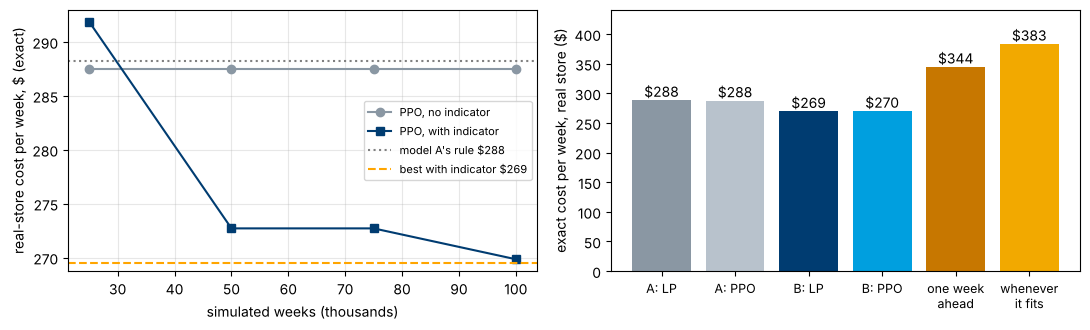

In [ ]:
WEEKS = 10_000                                             # test weeks: enough, since every policy sees the same weeks

def simulate(policy, weeks=WEEKS, seed=123):
    """Average cost per week of a policy on `weeks` simulated weeks of the real store (same random numbers for every policy)."""
    U = np.random.default_rng(seed).random((weeks, 3))     # columns: truck draw, demand draw, snow draw
    s, w, total, snow = 4, 0, 0.0, 0                       # start: 4 on the shelf, no snow
    for t in range(weeks):
        lo, hi = DEM[w]
        d = lo + int(U[t, 1] * (hi - lo + 1))              # this week's demand from the shared random number
        a = int(s < SMAX and U[t, 0] < policy(s, w))       # truck with probability P(truck | s, w)
        cost, s = week_cost(s, a, d)
        total += cost
        snow += w                                          # count snow weeks in this sample
        if U[t, 2] >= STAY:                                # the snow condition flips with probability 0.2
            w = 1 - w
    return total / weeks, snow / weeks

def one_week(s, w):
    """Look one week ahead only: send a truck if it pays this week."""
    return float(s < SMAX and cB[(s, w), 1] <= cB[(s, w), 0])

policies = {"no indicator: LP (model A)": lambda s, w: polA[(s,)],
            "no indicator: PPO": greedy(ppo_A, False),
            "with indicator: LP (model B)": lambda s, w: polB[(s, w)],
            "with indicator: PPO": greedy(ppo_B, True),
            "look one week ahead only": one_week,
            "truck whenever it fits": lambda s, w: 1.0}
rows = []
for name, policy in policies.items():
    sim, share = simulate(policy)                          # average over the same test weeks
    rows.append((name, sim, real_cost(policy)))            # ... and the exact long-run cost
print(f"{'policy':30s} {f'{WEEKS:,} weeks':>13s} {'exact':>9s} {'vs best':>9s}")
for name, sim, ex in rows:
    print(f"{name:30s} {sim:13.2f} {ex:9.2f} {ex / cost_B_real - 1:+9.1%}")
print(f"snow weeks in this sample: {share:.1%} (long run: 50%)")

# left: learning curves (exact real-store cost of PPO's greedy policy); right: exact cost of every policy
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot([k / 1000 for k, _ in log_A], [c for _, c in log_A], marker="o", color="#8A97A3", label="PPO, no indicator")
ax[0].plot([k / 1000 for k, _ in log_B], [c for _, c in log_B], marker="s", color="#003C71", label="PPO, with indicator")
ax[0].axhline(cost_A_real, ls=":", color="gray", label=f"model A's rule ${cost_A_real:.0f}")
ax[0].axhline(cost_B_real, ls="--", color="orange", label=f"best with indicator ${cost_B_real:.0f}")
ax[0].set_xlabel("simulated weeks (thousands)"); ax[0].set_ylabel("real-store cost per week, $ (exact)")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].bar(range(len(rows)), [ex for _, _, ex in rows], color=["#8A97A3", "#B8C2CC", "#003C71", "#009FDF", "#C77700", "#F2A900"])
ax[1].set_xticks(range(len(rows)))
ax[1].set_xticklabels(["A: LP", "A: PPO", "B: LP", "B: PPO", "one week\nahead", "whenever\nit fits"], fontsize=9)
ax[1].set_ylabel("exact cost per week, real store ($)"); ax[1].set_ylim(0, max(ex for _, _, ex in rows) * 1.15)
for i, (_, _, ex) in enumerate(rows):
    ax[1].text(i, ex + 6, f"${ex:.0f}", ha="center")      # value labels on the bars
plt.tight_layout(); plt.show()

**What to take away.**

- The snow indicator is a covariate in the state. It doubles the states (8 → 16) and the LP (15 → 30 variables), and cuts the weekly cost by 7% here.
- Looking one week ahead is not a good policy and that rule costs about 28% more.
- Compare policies on the environment that represents the real system: model A's own estimate of its cost is not what its rule costs in the store.

## 7. Things to try

- **A useless indicator:** set `DEM = {0: (0, 2), 1: (0, 2)}`. Both models give the same rule and the indicator is worth nothing.
- **Fickle snow cover:** set `STAY = 0.5`. The report still tells you this week's demand but nothing about next week's: how much is it worth now?
- **A cheaper courier:** set `COURIER = 200`. Running out matters less: how do the reorder points and the value of the indicator change?
- **Reward scale:** set `SCALE = 1.0` (rewards in dollars) and retrain: what happens to PPO?
- **Hide the indicator in the store:** train PPO on `SignalStore` but drop w from the observation. Given the stock alone, the weeks are no longer independent but w cannot be observed. Compare what PPO learns with the best single reorder point of Section 3.